# Bài toán XOR: không tách được tuyến tính trong không gian vào, tách được trong không gian ẩn (mục 9.1.2)

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([0, 1, 1, 0])
W1, b1 = np.array([[1.0, 1.0], [1.0, 1.0]]), np.array([-0.5, -1.5])   # nơ-ron ẩn OR và AND
W2, b2 = np.array([1.0, -1.0]), -0.5                                   # nơ-ron ra
step = lambda z: (z >= 0).astype(float)
H = step(X @ W1.T + b1)                      # biểu diễn ẩn (h1, h2)

def draw(ax, points, title, xlabel, ylabel):
    ax.scatter(points[y == 0, 0], points[y == 0, 1], s=180, marker='o', color='#D62728', label='XOR = 0', zorder=3)
    ax.scatter(points[y == 1, 0], points[y == 1, 1], s=180, marker='s', color='#1F77B4', label='XOR = 1', zorder=3)
    ax.set_xlim(-0.4, 1.4); ax.set_ylim(-0.4, 1.4); ax.set_aspect('equal'); ax.grid(alpha=0.3)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)

Vẽ hình và lưu ảnh.

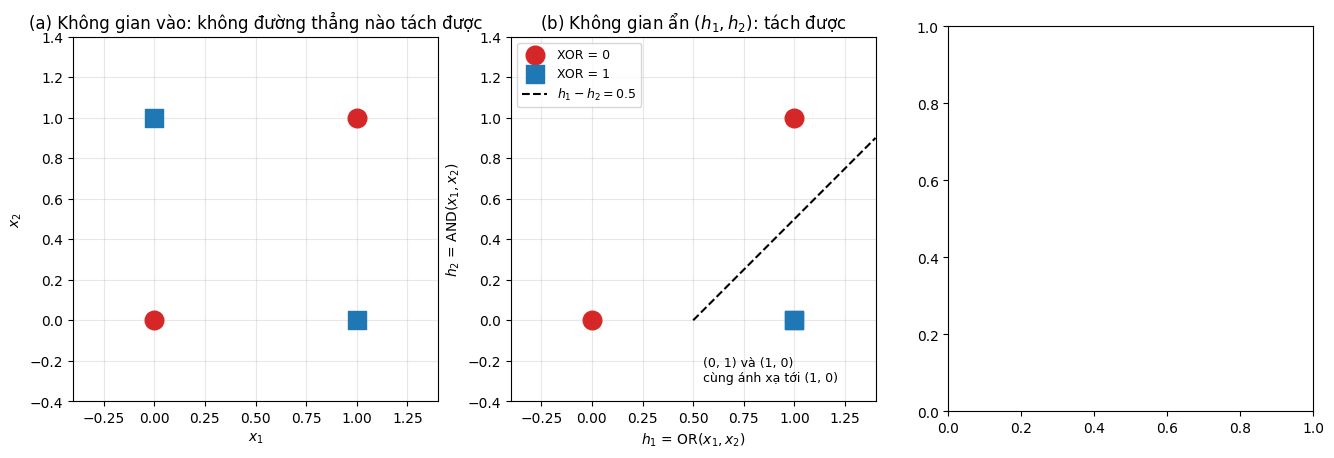

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
draw(axes[0], X, '(a) Không gian vào: không đường thẳng nào tách được', '$x_1$', '$x_2$')
draw(axes[1], H, '(b) Không gian ẩn $(h_1, h_2)$: tách được', '$h_1$ = OR($x_1, x_2$)', '$h_2$ = AND($x_1, x_2$)')
axes[1].plot([0.5, 1.4], [0, 0.9], 'k--', label='$h_1 - h_2 = 0.5$')
axes[1].annotate('(0, 1) và (1, 0)\ncùng ánh xạ tới (1, 0)', (1, 0), xytext=(0.55, -0.3), fontsize=9)
axes[1].legend(loc='upper left', fontsize=9)

(c) ranh giới quyết định của mạng trong không gian vào

In [3]:
xx, yy = np.meshgrid(np.linspace(-0.4, 1.4, 400), np.linspace(-0.4, 1.4, 400))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = step(step(grid @ W1.T + b1) @ W2 + b2).reshape(xx.shape)
axes[2].contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=['#F8D7DA', '#D6E4F5'])
draw(axes[2], X, '(c) Ranh giới của mạng 2 – 2 – 1', '$x_1$', '$x_2$')
axes[2].legend(loc='upper right', fontsize=9)
fig.tight_layout()
fig.savefig(IMAGES / 'xor.png', dpi=150)